optimal window for lin_acc: 5
optimal std for lin_acc: 2
optimal score for lin_acc: 79.23339575354886
optimal window for lin_acc_2: 3
optimal std for lin_acc_2: 1
optimal score for lin_acc_2: 60.40408939293933
optimal window for ang_vel_x: 5
optimal std for ang_vel_x: 2
optimal score for ang_vel_x: 79.23081265842889
optimal window for ang_vel_x_2: 3
optimal std for ang_vel_x_2: 1
optimal score for ang_vel_x_2: 70.85105585485019
optimal window for ang_vel_abs: 1
optimal std for ang_vel_abs: 1
optimal score for ang_vel_abs: 45.54468008545474
5
2
5
2
Index(['timestamp', 'timestamp_seconds', 'accelerometer_time',
       'accelerometer_seconds_elapsed', 'accelerometer_z', 'accelerometer_y',
       'accelerometer_x', 'gravity_time', 'gravity_seconds_elapsed',
       'gravity_z', 'gravity_y', 'gravity_x', 'location_time',
       'location_seconds_elapsed', 'location_altitude',
       'location_speedAccuracy', 'location_bearingAccuracy',
       'location_latitude', 'location_altitudeAboveMeanS

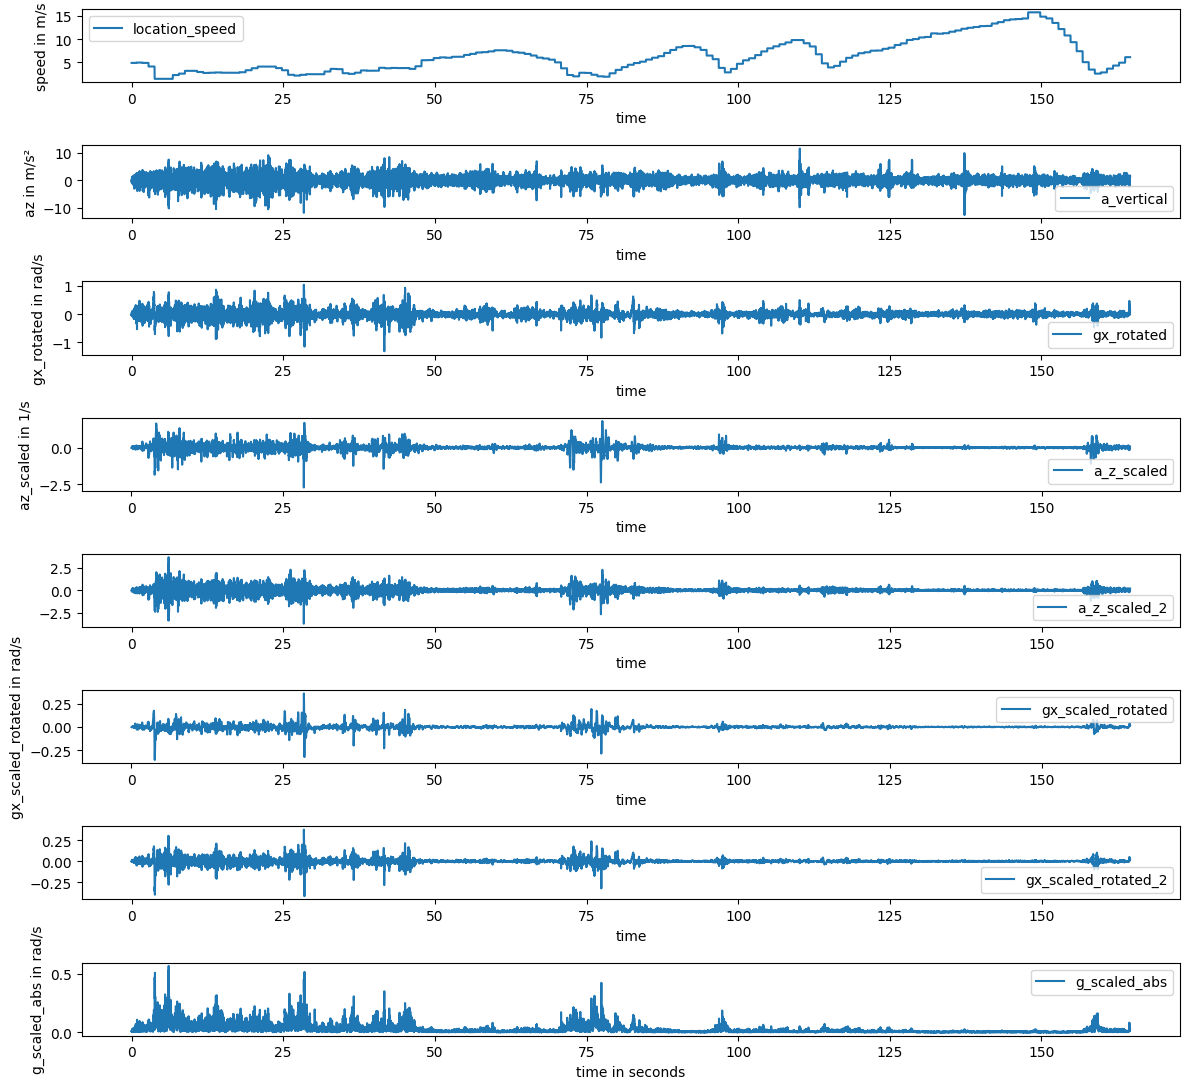

event
az_min: -1.8438376903050613 at time 3.823131799697876
az_max: 1.6435293566982394 at time 4.084028005599976
gx_min: -0.3522237125384006 at time 3.84320068359375
gx_max: 0.17321308954973777 at time 3.692683696746826
gxy_max: 0.5066823075888559 at time 3.8532350063323975
event
az_min: -0.768846849425988 at time 35.12078404426575
az_max: 0.6426965597481504 at time 35.180991411209106
gx_min: -0.06528982515945508 at time 34.86992025375366
gx_max: 0.13050406725215888 at time 35.12078404426575
gxy_max: 0.19814780313924713 at time 35.130817890167236
event
az_min: -1.446185330514577 at time 41.562957525253296
az_max: 0.8047782636016779 at time 41.45257759094238
gx_min: -0.22743477945160745 at time 41.64323353767395
gx_max: 0.1519789806558087 at time 41.572991609573364
gxy_max: 0.3491534383647686 at time 41.663302421569824
event
az_min: -1.5005488524714166 at time 72.85063695907593
az_max: 1.1837553096119662 at time 72.51949858665466
gx_min: -0.09686397698887061 at time 72.33887648582458
gx

In [9]:
import os
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import math

desktop_path = r"C:\Users\stratklar\Documents\Markus\ASA\Indien\mobile_data\sample1"

def get_event_list():
    if desktop_path.endswith("1"):
        event_list = [3, 34, 40, 71, 78, 98, 159]
    elif desktop_path.endswith("2"):
        event_list = [16, 20, 30]
    elif desktop_path.endswith("3"):
        event_list = [132, 140, 199, 211]
    else:
        event_list = []
    return event_list

df = pd.read_csv(os.path.join(desktop_path, "synchronization2.csv"))

if desktop_path.endswith("2"):
    df["gravity_x"] = 0
    df["gravity_y"] = 0
    df["gravity_z"] = 1

#method 1: try to identify roll-axis as horizontal direction with least variance of angular_velocity. After that, take perpendicular axis
#method 2: maximise ratio of range in the neighborhood of labelled road anomalies and global standard deviation. Not in use atm
def estimate_least_varying_horizontal_axis(df):
    # Gyroscope in phone coordinates, typically rad/s
    #expected to be orthogonal to gravity and bearing direction
    gyro = df[
        ['gyroscope_x', 'gyroscope_y', 'gyroscope_z']
    ].to_numpy(dtype=float)

    gravity = df[
        ['gravity_x', 'gravity_y', 'gravity_z']
    ].to_numpy(dtype=float)

    valid = (
        np.isfinite(gyro).all(axis=1)
        & np.isfinite(gravity).all(axis=1)
    )
    gyro = gyro[valid]
    gravity = gravity[valid]

    # Approximate phone vertical using mean gravity.
    # Gravity points downward; its sign does not affect the plane.
    g_mean = gravity.mean(axis=0)
    g_mean /= np.linalg.norm(g_mean)

    # Construct two orthonormal basis vectors perpendicular to gravity
    seed = np.array([1., 0., 0.])
    if abs(np.dot(seed, g_mean)) > 0.9:
        seed = np.array([0., 1., 0.])

    b1 = seed - np.dot(seed, g_mean) * g_mean
    b1 /= np.linalg.norm(b1)
    b2 = np.cross(g_mean, b1)

    B = np.column_stack([b1, b2])

    # Remove gyroscope bias / mean before calculating covariance
    gyro_centered = gyro - gyro.mean(axis=0)
    gyro_horizontal = gyro_centered @ B

    C = np.cov(gyro_horizontal, rowvar=False)
    eigenvalues, eigenvectors = np.linalg.eigh(C)

    # Smallest-variance direction in the horizontal plane
    axis_phone = B @ eigenvectors[:, 0]
    axis_phone /= np.linalg.norm(axis_phone)

    return axis_phone, eigenvalues

#default definition of weighted_sum parameters for linear acceleration (az) and angular velocity (std)
"""
x_az = np.arange(-5,6)
x_gx = np.arange(-5,6)
std_az = 2
std_gx = 2
weights_az = np.exp(-x_az**2 / (2 * std_az**2))
weights_az /= weights_az.sum()
weights_gx = np.exp(-x_gx**2 / (2 * std_gx**2))
weights_gx /= weights_gx.sum()
"""
df["time"] = df["timestamp_seconds"] - df["timestamp_seconds"].min()
df["dt"] = df["time"].diff().abs()
df["a_mag"] = np.sqrt(df["accelerometer_z"]**2 + df["accelerometer_y"]**2 + df["accelerometer_x"]**2)
df["g_mag"] = np.sqrt(df["gyroscope_z"]**2 + df["gyroscope_y"]**2 + df["gyroscope_x"]**2)
df = df[df["location_speed"] > 1]
#df[mobile/vehicle/world_coordinate_sytem]

#calculating yaw-axis:
df["gravity_abs"] = np.sqrt(df["gravity_z"]**2 + df["gravity_y"]**2 + df["gravity_x"]**2)
df["gravity_x_scaled"] = df["gravity_x"] / df["gravity_abs"]
df["gravity_y_scaled"] = df["gravity_y"] / df["gravity_abs"]
df["gravity_z_scaled"] = df["gravity_z"] / df["gravity_abs"]
df["a_vertical"] = -(df["accelerometer_x"] * df["gravity_x"] + df["accelerometer_y"] * df["gravity_y"] + df["accelerometer_z"] * df["gravity_z"]) / df["gravity_abs"]

#pick axis orthogonal to axis with least variance of angular velocity
roll_axis_test, eigenvalues = estimate_least_varying_horizontal_axis(df)
x_axis = np.array([1,0,0])
gxm = df["gravity_x"].mean()
gym = df["gravity_y"].mean()
gzm = df["gravity_z"].mean()
z_axis = np.array([gxm, gym, gzm]) / np.sqrt(gxm**2 + gym**2 + gzm**2)
pitch_axis_test_unscaled = x_axis - np.dot(roll_axis_test, x_axis) * roll_axis_test - np.dot(z_axis, x_axis) * z_axis
pitch_axis_test = pitch_axis_test_unscaled / np.linalg.norm(pitch_axis_test_unscaled)
df["gx_rotated"] = np.dot(pitch_axis_test, [df["gyroscope_x"], df["gyroscope_y"], df["gyroscope_z"]])
#df["g_pitch_2_scaled"] = df["g_pitch_2"].rolling(11, center=True).apply(lambda x: np.dot(x, weights_gx), raw=True) / df["location_speed"].rolling(11, center=True).apply(lambda x: np.dot(x, weights_gx), raw=True)

#take absolute value of horizontal angular velocity
df["gravity_abs"] = np.sqrt(df["gravity_x"]**2 + df["gravity_y"]**2 + df["gravity_z"]**2)
df["ang_vel_abs"] = np.sqrt(df["gyroscope_x"]**2 + df["gyroscope_y"]**2 + df["gyroscope_z"]**2 - ((df["gyroscope_x"] * df["gravity_x"] + df["gyroscope_y"] * df["gravity_y"] + df["gyroscope_z"] * df["gravity_z"]) / df["gravity_abs"])**2)

#setting number of considered values and standard deviation for smoothing such that ratio of local and global deviation is maximal.
def find_optimal_hyperparameters(event_timestamps, column = "lin_acc"):
    optimal_window = 1
    optimal_std = 1
    range_sum = 0

    #swap for- and if-loop for more computational efficiency
    for event in event_timestamps:
        if(column in ["lin_acc", "lin_acc_2"]):
            range_sum += (df[(df["time"] > event - 2) & (df["time"] < event + 2)]["a_vertical"].max() - df[(df["time"] > event - 2) & (df["time"] < event + 2)]["a_vertical"].min()) / df["a_vertical"].std()
        elif(column in ["ang_vel_x", "ang_vel_x_2"]):
            range_sum += (df[(df["time"] > event - 2) & (df["time"] < event + 2)]["gx_rotated"].max() - df[(df["time"] > event - 2) & (df["time"] < event + 2)]["gx_rotated"].min()) / df["gx_rotated"].std()
        elif(column == "ang_vel_abs"):
            mu = df["ang_vel_abs"].mean()
            range_sum += (df[(df["time"] > event - 2) & (df["time"] < event + 2)]["ang_vel_abs"].max() - mu) / df["ang_vel_abs"].std()
        else:
            return optimal_window, optimal_std

    optimal_score = range_sum
    
    for i in [1,2,3,4,5,6,7,8,9,10,20,50]:
         for std in [1,2,3,4,5,10]:
            range_sum = 0

            value_range = np.arange(-i,i+1)
            weights = np.exp(-value_range**2 / (2 * std**2))
            weights /= weights.sum()

            if column == "lin_acc":                    
                df["scaled_test"] = df["a_vertical"].rolling(2*i+1, center=True).apply(lambda x: np.dot(x, weights), raw=True) / df["location_speed"].rolling(2*i+1, center=True).apply(lambda x: np.dot(x, weights), raw=True)
            elif column == "lin_acc_2":
                df["a_z_scaled_pos"] = df["a_vertical"].rolling(2*i+1, center=True).apply(lambda x: np.dot(np.maximum(x, 0), weights), raw=True) / df["location_speed"].rolling(2*i+1, center=True).apply(lambda x: np.dot(x, weights), raw=True)
                df["a_z_scaled_neg"] = df["a_vertical"].rolling(2*i+1, center=True).apply(lambda x: np.dot(np.maximum(-x, 0), weights), raw=True) / df["location_speed"].rolling(2*i+1, center=True).apply(lambda x: np.dot(x, weights), raw=True)
                df["scaled_test"] = np.maximum(df["a_z_scaled_pos"], df["a_z_scaled_neg"]) * np.sign(df["a_z_scaled_pos"] - df["a_z_scaled_neg"])
            elif column == "ang_vel_x":
                df["scaled_test"] = df["gx_rotated"].rolling(2*i+1, center=True).apply(lambda x: np.dot(x, weights), raw=True) / df["location_speed"].rolling(2*i+1, center=True).apply(lambda x: np.dot(x, weights), raw=True)
            elif column == "ang_vel_x_2":
                df["gx_scaled_pos"] = df["gx_rotated"].rolling(2*i+1, center=True).apply(lambda x: np.dot(np.maximum(x, 0), weights), raw=True) / df["location_speed"].rolling(2*i+1, center=True).apply(lambda x: np.dot(x, weights), raw=True)
                df["gx_scaled_neg"] = df["gx_rotated"].rolling(2*i+1, center=True).apply(lambda x: np.dot(np.maximum(-x, 0), weights), raw=True) / df["location_speed"].rolling(2*i+1, center=True).apply(lambda x: np.dot(x, weights), raw=True)
                df["scaled_test"] = np.maximum(df["gx_scaled_pos"], df["gx_scaled_neg"]) * np.sign(df["gx_scaled_pos"] - df["gx_scaled_neg"])
            elif column == "ang_vel_abs":
                df["scaled_test"] = df["ang_vel_abs"].rolling(2*i+1, center=True).apply(lambda x: np.dot(x, weights), raw=True) / df["location_speed"].rolling(2*i+1, center=True).apply(lambda x: np.dot(x, weights), raw=True)
                mu = df["ang_vel_abs"].mean()
                for event in event_timestamps:
                    range_sum += df[(df["time"] > event - 2) & (df["time"] < event + 2)]["scaled_test"].max() - mu               
                score = range_sum / df["scaled_test"].std()
            else:
                optimal_window = 1
                optimal_std = 1
                return optimal_window, optimal_std

            if column != "ang_vel_abs":
                for event in event_timestamps:
                    range_sum += (df[(df["time"] > event - 2) & (df["time"] < event + 2)]["scaled_test"].max() - df[(df["time"] > event - 2) & (df["time"] < event + 2)]["scaled_test"].min())

                score = range_sum / df["scaled_test"].std()
            if score > optimal_score:
                optimal_window = 2 * i + 1
                optimal_std = std
                optimal_score = score

    print(f"optimal window for {column}: {optimal_window}")
    print(f"optimal std for {column}: {optimal_std}")
    print(f"optimal score for {column}: {optimal_score}")
    return optimal_window, optimal_std

"""
#calculating roll-axis:
w = df["orientation_qw"]
x = df["orientation_qx"]
y = df["orientation_qy"]
z = df["orientation_qz"]

#rotation matrix to map phone-vectors to world-vectors
R_wp = np.array([
        [1 - 2*(y*y + z*z), 2*(x*y - z*w),     2*(x*z + y*w)],
        [2*(x*y + z*w),     1 - 2*(x*x + z*z), 2*(y*z - x*w)],
        [2*(x*z - y*w),     2*(y*z + x*w),     1 - 2*(x*x + y*y)]
    ])

#location_bearing represents horizontal direction of driving with bearing = 0 north and bearing = 90 east.
pitch_axis_world = np.array([
        np.cos(df["location_bearing"] / 180 * math.pi), -np.sin(df["location_bearing"] / 180 * math.pi), 0.0
    ]) #unit vector to the right of the car with respect to global coordinate system

df["pitch_axis"] = R_wp.T @ pitch_axis_world
"""

#location_bearing data provides horizontal direction of driving with bearing = 0 north and bearing = 90 east.
df["vehicle_lateral_x"] = np.cos(df["location_bearing"] / 180 * math.pi) #unit vector to the right of the car with respect to global coordinate system
df["vehicle_lateral_y"] = -np.sin(df["location_bearing"] / 180 * math.pi)

#calculate R_T @ pitch_axis_world to map vectors from the coordinate system with respect to the world to the coordinate system with respect to the phone. R_T is the inverse of the rotation matrix to map phone-vectors to world-vectors.
df["vehicle_pitch_x"] = (1 - 2*(df["orientation_qy"]*df["orientation_qy"] + df["orientation_qz"]*df["orientation_qz"])) * df["vehicle_lateral_x"] + 2*(df["orientation_qx"]*df["orientation_qy"] + df["orientation_qz"]*df["orientation_qw"])  * df["vehicle_lateral_y"]
df["vehicle_pitch_y"] = 2*(df["orientation_qx"]*df["orientation_qy"] - df["orientation_qz"]*df["orientation_qw"]) * df["vehicle_lateral_x"] + (1 - 2*(df["orientation_qx"]*df["orientation_qx"] + df["orientation_qz"]*df["orientation_qz"])) * df["vehicle_lateral_y"]
df["vehicle_pitch_z"] = 2*(df["orientation_qx"]*df["orientation_qz"] + df["orientation_qy"]*df["orientation_qw"]) * df["vehicle_lateral_x"] + 2*(df["orientation_qy"]*df["orientation_qz"] - df["orientation_qx"]*df["orientation_qw"]) * df["vehicle_lateral_y"]
df["vehicle_pitch_abs"] = np.sqrt(df["vehicle_pitch_x"]**2 + df["vehicle_pitch_y"]**2 + df["vehicle_pitch_z"]**2)
df["g_pitch"] = (df["gyroscope_x"] * df["vehicle_pitch_x"] + df["gyroscope_y"] * df["vehicle_pitch_y"] + df["gyroscope_z"] * df["vehicle_pitch_z"]) / df["vehicle_pitch_abs"]

"""
#df["bearing*gravity"] = df["bearing_east"] * df["gravity_x_scaled"] + df["bearing_north"] * df["gravity_y_scaled"]
df["driving_direction_x"] = df["bearing_east"] - 
df["driving_direction_y"] = 
df["driving_direction_z"] = 0

#calculating pitch-axis:
df["pitch_axis_x_tmp"] = 1 - df["driving_direction_x"] * df["driving_direction_x"] - df["gravity_direction_x"] * df["gravity_direction_x"]
df["pitch_axis_y_tmp"] = - df["driving_direction_x"] * df["driving_direction_y"] - df["gravity_direction_x"] * df["gravity_direction_y"]
df["pitch_axis_z_tmp"] = - df["driving_direction_x"] * df["driving_direction_z"] - df["gravity_direction_x"] * df["gravity_direction_z"]

df["pitch_abs"] = np.sqrt(df["pitch_axis_x_tmp"]**2 + df["pitch_axis_y_tmp"]**2 + df["pitch_axis_z_tmp"]**2)
df["pitch_axis_x"] = df["pitch_axis_x_tmp"] / df["pitch_abs"]
df["pitch_axis_y"] = df["pitch_axis_y_tmp"] / df["pitch_abs"]
df["pitch_axis_z"] = df["pitch_axis_z_tmp"] / df["pitch_abs"]
"""

window_lin_acc, std_lin_acc = find_optimal_hyperparameters(event_timestamps = get_event_list(), column = "lin_acc")
window_lin_acc_2, std_lin_acc_2 = find_optimal_hyperparameters(event_timestamps = get_event_list(), column = "lin_acc_2")
window_ang_vel, std_ang_vel = find_optimal_hyperparameters(event_timestamps = get_event_list(), column = "ang_vel_x")
window_ang_vel_2, std_ang_vel_2 = find_optimal_hyperparameters(event_timestamps = get_event_list(), column = "ang_vel_x_2")
window_ang_vel_abs, std_ang_vel_abs = find_optimal_hyperparameters(event_timestamps = get_event_list(), column = "ang_vel_abs")
x_az = np.arange(- (window_lin_acc - 1) / 2, (window_lin_acc + 1) / 2)
x_az_2 = np.arange(- (window_lin_acc_2 - 1) / 2, (window_lin_acc_2 + 1) / 2)
x_gx = np.arange(- (window_ang_vel - 1) / 2, (window_ang_vel + 1) / 2)
x_gx_2 = np.arange(- (window_ang_vel_2 - 1) / 2, (window_ang_vel_2 + 1) / 2)
x_g_abs = np.arange(- (window_ang_vel_abs - 1) / 2, (window_ang_vel_abs + 1) / 2)
#std_az = 2
#std_gx = 2
weights_az = np.exp(-x_az**2 / (2 * std_lin_acc**2))
weights_az /= weights_az.sum()
weights_az_2 = np.exp(-x_az_2**2 / (2 * std_lin_acc_2**2))
weights_az_2 /= weights_az_2.sum()
weights_gx = np.exp(-x_gx**2 / (2 * std_ang_vel**2))
weights_gx /= weights_gx.sum()
weights_gx_2 = np.exp(-x_gx_2**2 / (2 * std_ang_vel_2**2))
weights_gx_2 /= weights_gx_2.sum()
weights_g_abs = np.exp(-x_g_abs**2 / (2 * std_ang_vel_abs**2))
weights_g_abs /= weights_g_abs.sum()

df["a_z_scaled"] = df["a_vertical"].rolling(window_lin_acc, center=True).apply(lambda x: np.dot(x, weights_az), raw=True) / df["location_speed"].rolling(window_lin_acc, center=True).apply(lambda x: np.dot(x, weights_az), raw=True)
df["a_z_scaled_pos"] = df["a_vertical"].rolling(window_lin_acc_2, center=True).apply(lambda x: np.dot(np.maximum(x, 0), weights_az_2), raw=True) / df["location_speed"].rolling(window_lin_acc_2, center=True).apply(lambda x: np.dot(x, weights_az_2), raw=True)
df["a_z_scaled_neg"] = df["a_vertical"].rolling(window_lin_acc_2, center=True).apply(lambda x: np.dot(np.maximum(-x, 0), weights_az_2), raw=True) / df["location_speed"].rolling(window_lin_acc_2, center=True).apply(lambda x: np.dot(x, weights_az_2), raw=True)
df["a_z_scaled_2"] = np.maximum(df["a_z_scaled_pos"], df["a_z_scaled_neg"]) * np.sign(df["a_z_scaled_pos"] - df["a_z_scaled_neg"])
#TODO: calculate bearing to obtain x-axis wrt horizontal direction of driving. Calibration would be necessary
#df["gx_scaled"] = df["gyroscope_x"].rolling(11, center=True).apply(lambda x: np.dot(x, weights_gx), raw=True) / df["location_speed"].rolling(11, center=True).apply(lambda x: np.dot(x, weights_gx), raw=True)
#df["g_pitch_scaled"] = df["g_pitch"].rolling(11, center=True).apply(lambda x: np.dot(x, weights_gx), raw=True) / df["location_speed"].rolling(11, center=True).apply(lambda x: np.dot(x, weights_gx), raw=True)
df["gx_scaled_rotated"] = df["gx_rotated"].rolling(window_ang_vel, center=True).apply(lambda x: np.dot(x, weights_gx), raw=True) / df["location_speed"].rolling(window_ang_vel, center=True).apply(lambda x: np.dot(x, weights_gx), raw=True)
df["gx_scaled_pos"] = df["gx_rotated"].rolling(window_ang_vel_2, center=True).apply(lambda x: np.dot(np.maximum(x, 0), weights_gx_2), raw=True) / df["location_speed"].rolling(window_ang_vel_2, center=True).apply(lambda x: np.dot(x, weights_gx_2), raw=True)
df["gx_scaled_neg"] = df["gx_rotated"].rolling(window_ang_vel_2, center=True).apply(lambda x: np.dot(np.maximum(-x, 0), weights_gx_2), raw=True) / df["location_speed"].rolling(window_ang_vel_2, center=True).apply(lambda x: np.dot(x, weights_gx_2), raw=True)
df["gx_scaled_rotated_2"] = np.maximum(df["gx_scaled_pos"], df["gx_scaled_neg"]) * np.sign(df["gx_scaled_pos"] - df["gx_scaled_neg"])
df["g_scaled_abs"] = df["ang_vel_abs"].rolling(window_ang_vel_abs, center=True).apply(lambda x: np.dot(x, weights_g_abs), raw=True) / df["location_speed"].rolling(window_ang_vel_abs, center=True).apply(lambda x: np.dot(x, weights_g_abs), raw=True)

df["a_horizontal_x_axis_x"] = 1 - df["gravity_x"] * df["gravity_x"]
df["a_horizontal_x_axis_y"] = - df["gravity_x"] * df["gravity_y"]
df["a_horizontal_x_axis_z"] = - df["gravity_x"] * df["gravity_z"]
df["a_horizontal_x_axis_abs"] = np.sqrt(df["a_horizontal_x_axis_x"]**2 + df["a_horizontal_x_axis_y"]**2 + df["a_horizontal_x_axis_z"]**2)
df["a_x_x"] = df["a_horizontal_x_axis_x"] / df["a_horizontal_x_axis_abs"]
df["a_x_y"] = df["a_horizontal_x_axis_y"] / df["a_horizontal_x_axis_abs"]
df["a_x_z"] = df["a_horizontal_x_axis_z"] / df["a_horizontal_x_axis_abs"]

df["a_horizontal_y_axis_x"] = - df["gravity_y"]* df["gravity_x"]
df["a_horizontal_y_axis_y"] = 1 - df["gravity_y"] * df["gravity_y"]
df["a_horizontal_y_axis_z"] = - df["gravity_y"] * df["gravity_z"]
df["a_horizontal_y_axis_abs"] = np.sqrt(df["a_horizontal_y_axis_x"]**2 + df["a_horizontal_y_axis_y"]**2 + df["a_horizontal_y_axis_z"]**2)
df["a_y_x"] = df["a_horizontal_y_axis_x"] / df["a_horizontal_y_axis_abs"]
df["a_y_y"] = df["a_horizontal_y_axis_y"] / df["a_horizontal_y_axis_abs"]
df["a_y_z"] = df["a_horizontal_y_axis_z"] / df["a_horizontal_y_axis_abs"]

print(window_lin_acc)
print(std_lin_acc)
print(window_ang_vel)
print(std_ang_vel)

#df["g_pitch_2"] = df["pitch_axis_test"][0] * df["gyroscope_x"] + df["pitch_axis_test"][1] * df["gyroscope_y"] + df["pitch_axis_test"] * df["gyroscope_z"]
fig, axes = plt.subplots(8, 1, figsize=(12, 11))

print(df.columns)
print(roll_axis_test)

df.plot("time", "location_speed", ax = axes[0])
df.plot(x = "time", y = "a_vertical", ax = axes[1])
df.plot("time", "gx_rotated", ax = axes[2])
df.plot("time", "a_z_scaled", ax = axes[3])
df.plot("time", "a_z_scaled_2", ax = axes[4])
df.plot("time", "gx_scaled_rotated", ax = axes[5])
df.plot("time", "gx_scaled_rotated_2", ax = axes[6])
df.plot("time", "g_scaled_abs", ax = axes[7])
#df.plot("time", "orientation_roll") #orientation_roll and orientation_pitch are swapped in the dataset
#df.plot("time", "gyroscope_z", ax = axes[6])

axes[0].set_ylabel("speed in m/s")
axes[1].set_ylabel("az in m/s²")
axes[2].set_ylabel("gx_rotated in rad/s")
axes[3].set_ylabel("az_scaled in 1/s")
axes[5].set_ylabel("gx_scaled_rotated in rad/s")
#axes[4].set_ylabel("orientation_roll")
axes[7].set_ylabel("g_scaled_abs in rad/s")
axes[7].set_xlabel("time in seconds")

plt.tight_layout()
plt.show()

def identify_peaks(events):
    z = 0
    az_peak_duration = 0
    gx_peak_duration = 0
    az_min_gx_max_distance = 0

    #average delay of parameters relative to az_min
    az_max_delay = 0
    gx_min_delay = 0
    gx_max_delay = 0
    gxy_delay = 0
    for event in events:
        z += 1
        print("event")
        df_event = df[(df["time"] > event - 2) & (df["time"] < event + 2)]
        peak_min_az = df_event.loc[df_event["a_z_scaled"].idxmin(), "time"]
        peak_max_az = df_event.loc[df_event["a_z_scaled"].idxmax(), "time"]
        print(f"az_min: {df_event['a_z_scaled'].min()} at time {peak_min_az}")
        print(f"az_max: {df_event['a_z_scaled'].max()} at time {peak_max_az}")
        az_peak_duration += abs(peak_max_az - peak_min_az)

        peak_min_gx = df_event.loc[df_event["gx_scaled_rotated"].idxmin(), "time"]
        peak_max_gx = df_event.loc[df_event["gx_scaled_rotated"].idxmax(), "time"]
        print(f"gx_min: {df_event['gx_scaled_rotated'].min()} at time {peak_min_gx}")
        print(f"gx_max: {df_event['gx_scaled_rotated'].max()} at time {peak_max_gx}")
        gx_peak_duration += abs(peak_max_gx - peak_min_gx)
        az_min_gx_max_distance += abs(peak_max_gx - peak_min_az)

        peak_max_gxy = df_event.loc[df_event["g_scaled_abs"].idxmax(), "time"]
        print(f"gxy_max: {df_event['g_scaled_abs'].max()} at time {peak_max_gxy}")

        az_max_delay += peak_max_az - peak_min_az
        gx_min_delay += peak_min_gx - peak_min_az
        gx_max_delay += peak_max_gx - peak_min_az
        gxy_delay += peak_max_gxy - peak_min_az

    if z > 0:
        print(f"az_peak_duration: {az_peak_duration / z}")
        print(f"gx_peak_duration: {gx_peak_duration / z}")
        print(f"az_min_gx_max_distance: {az_min_gx_max_distance / z}")
        print(f"az_max_delay: {az_max_delay / z}")
        print(f"gx_min_delay: {gx_min_delay / z}")
        print(f"gx_max_delay: {gx_max_delay / z}")
        print(f"gxy_delay: {gxy_delay / z}")


identify_peaks(get_event_list())